# Training-free token pruning for ViT-Base, part 1: attention scoring, the wrapper, correctness

`vit_base_patch16_224` (timm, pretrained) processes 196 patch tokens + CLS through all 12 blocks.
Idea: at a middle block, use the **CLS token's attention row** as a free per-patch importance score,
drop the lowest-scoring patches, and run the remaining blocks on the shorter sequence. No training.

1. Expose the attention matrix from timm's fused attention (eager path + hook on `attn_drop`)
2. Score patches from the CLS row (mean over heads) and pick which to drop
3. `PrunedViT` wrapper, verified exact at 0% dropped
4. Prediction agreement and accuracy on a 200-image Imagenette subset

CPU is enough for this part (the recorded run used a GPU). Outputs are from the recorded run.

In [ ]:
!pip install timm --quiet
!pip uninstall -y torchao -q

In [1]:
import torch
import timm
import urllib.request
from PIL import Image

device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device:{device}")
print(f"timm: {timm.__version__}, torch: {torch.__version__}")

device:cuda
timm: 1.0.30, torch: 2.11.0+cu130


## 1. Load the model, a sample image, and capture block 6's attention

In [2]:
import torch
import timm
import urllib.request
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image
import os

device = "cuda" if torch.cuda.is_available() else "cpu"
TARGET_LAYER = 6  # same as Day 1 — 0-indexed block index
LAYERS, KS = [3, 6, 9], [0.1, 0.2, 0.3, 0.5] #(run the experiment once at each of 10%, 20%, 30% and 50%)
#and K is drop fraction;K=0.3 means "drop the lowest-scoring 30% of patches(58 of 196 dropped, 138 kept)"
WARMUP, ROUNDS, ITERS = 10, 7, 15


# --- Day 1 recap: load model, image, run forward with the attention hook ---
model = timm.create_model("vit_base_patch16_224", pretrained=True)
model.eval().to(device)

img_path, _ = urllib.request.urlretrieve(
    "https://github.com/pytorch/hub/raw/master/images/dog.jpg", "sample.jpg"
)
img = Image.open(img_path).convert("RGB")

config = timm.data.resolve_data_config({}, model=model) #this gets the normalization mean/std, without hand rolling.
transform = timm.data.create_transform(**config) #this transforms the inputs to the specified normalization
x = transform(img).unsqueeze(0).to(device) #adds batch dimension to conver to 4D batch tensor of shape (1, 3, 224, 224)
print(x.shape)

target_attn_module = model.blocks[TARGET_LAYER].attn
target_attn_module.fused_attn = False

captured = {}
def capture_attn_hook(module, inputs, output):
    captured["attn_weights"] = inputs[0].detach()
    return captured["attn_weights"]
handle = target_attn_module.attn_drop.register_forward_hook(capture_attn_hook)
attn_weight = capture_attn_hook(target_attn_module, (torch.randn(1, 12, 197, 197),), None)
#print(attn_weight)


with torch.no_grad():
    _ = model(x)
handle.remove()

attn_weights = captured["attn_weights"]
print(f"attn_weights shape: {attn_weights.shape}")  # (1, 12, 197, 197)

torch.Size([1, 3, 224, 224])
attn_weights shape: torch.Size([1, 12, 197, 197])


In [ ]:
##Sanity Check: baseline inference on known image.
#Standard pytorch-hub sample image + labels file, so predictions are independently checkable
img_path, _ = urllib.request.urlretrieve(
    "https://github.com/pytorch/hub/raw/master/images/dog.jpg", "sample.jpg"
)
labels_path, _ = urllib.request.urlretrieve(
    "https://raw.githubusercontent.com/pytorch/hub/master/imagenet_classes.txt", "imagenet_classes.txt"
)
with open(labels_path) as f:
    imagenet_classes = [line.strip() for line in f.readlines()]

img = Image.open(img_path).convert("RGB")
img

In [ ]:
#timm gives you exact preprocessing this checkpoint expects - don't hand-roll your own
#normalization/resize, it's a common source of silently-wrong predictions.
config = timm.data.resolve_data_config({}, model=model)
transform = timm.data.create_transform(**config)

x = transform(img).unsqueeze(0).to(device) #(1,3,244,244)
print(f"input shape: {x.shape}")

with torch.no_grad():
  logits = model(x)

top5 = logits.softmax(dim=-1)[0].topk(5)
print("top-5 predictions:")
for prob, idx in zip(top5.values, top5.indices):
  print(f"..{imagenet_classes[idx]:<25s} {prob.item():.3f}")

timm's default attention calls `F.scaled_dot_product_attention`, which never materializes the
(B, heads, 197, 197) matrix. Setting `fused_attn = False` on **one** block forces the eager path; the
input to `attn_drop` is then exactly the post-softmax attention (dropout is a no-op in eval).

In [3]:
TARGET_LAYER = 6  # 0-indexed; "layer 6 of 12" in the plan means block index 5, adjust if you prefer 1-indexed counting

target_attn_module = model.blocks[TARGET_LAYER].attn

# Force eager attention on this block only — leave the rest of the model fused (faster) since
# we only need to *read* attention at the target layer, not everywhere.
target_attn_module.fused_attn = False


captured = {}

def capture_attn_hook(module, inputs, output):
    # inputs[0] is the attention matrix going INTO attn_drop, shape (B, heads, N, N)
    captured["attn_weights"] = inputs[0].detach()

handle = target_attn_module.attn_drop.register_forward_hook(capture_attn_hook)

with torch.no_grad():
    _ = model(x)

handle.remove()

attn_weights = captured["attn_weights"]
print(f"captured attention shape: {attn_weights.shape}")  # expect (1, num_heads, 197, 197) for 224px/patch16 (196 patches + CLS)
print(f"rows sum to ~1 (softmax check): {attn_weights[0, 0, 0].sum().item():.4f}")

captured attention shape: torch.Size([1, 12, 197, 197])
rows sum to ~1 (softmax check): 1.0000


## Averaging heads & extracting the CLS row

`attn_weights` is `(B, heads, N, N)` — for every head, row `i` is "how much token `i` attends to every other token." We want one score per patch, so:
1. Average across the 12 heads (dim=1) — different heads specialize differently, averaging gives a consensus importance score.
2. Take row 0 (the CLS token's row) — that's how much the CLS token attends to every other token, including itself.
3. Drop index 0 from that row (CLS attending to itself) — we only care about its attention over the 196 *patch* tokens, since those are the pruning candidates.

In [4]:
mean_attn = attn_weights.mean(dim=1)          # (1, 197, 197) — averaged over heads
cls_row = mean_attn[0, 0, :]                   # (197,) — CLS token's attention over everything
cls_to_patches = cls_row[1:]                   # (196,) — drop CLS-to-CLS entry, keep only patches

print(f"cls_to_patches shape: {cls_to_patches.shape}")
print(f"min={cls_to_patches.min().item():.5f}  max={cls_to_patches.max().item():.5f}  mean={cls_to_patches.mean().item():.5f}")
print(f"sum over 196 patches: {cls_to_patches.sum().item():.4f}  (won't be exactly 1.0 — we dropped the CLS-to-CLS mass)")

cls_to_patches shape: torch.Size([196])
min=0.00029  max=0.05624  mean=0.00289
sum over 196 patches: 0.5660  (won't be exactly 1.0 — we dropped the CLS-to-CLS mass)


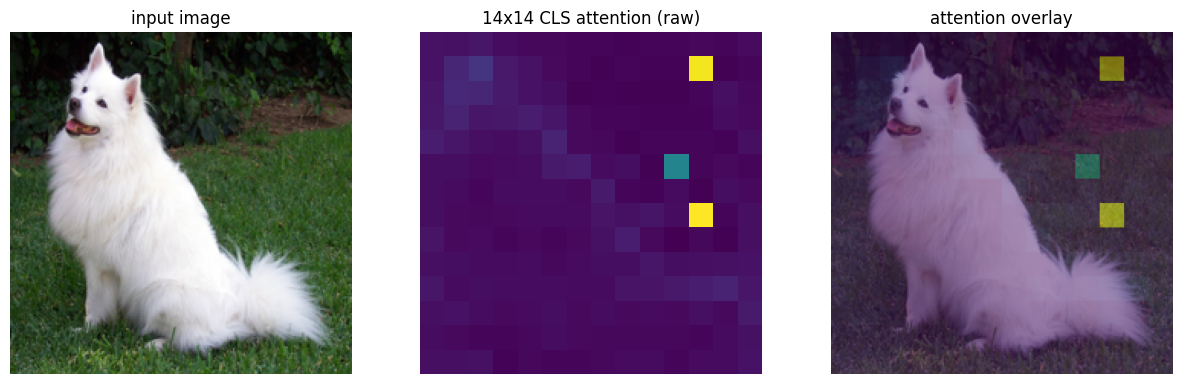

In [5]:
# Visual sanity check: does CLS attention actually land on the dog, not the background?
grid_h, grid_w = model.patch_embed.grid_size    # (14, 14) for 224px / patch16
heatmap = cls_to_patches.reshape(grid_h, grid_w).cpu().numpy()

display_img = np.array(img.resize((224, 224)))
heatmap_upsampled = np.kron(heatmap, np.ones((16, 16)))  # 14x14 -> 224x224, blocky upsample matching patch size

fig, axes = plt.subplots(1, 3, figsize=(15, 5))
axes[0].imshow(display_img)
axes[0].set_title("input image")
axes[1].imshow(heatmap, cmap="viridis")
axes[1].set_title("14x14 CLS attention (raw)")
axes[2].imshow(display_img)
axes[2].imshow(heatmap_upsampled, cmap="viridis", alpha=0.5)
axes[2].set_title("attention overlay")
for ax in axes:
    ax.axis("off")
plt.show()

The raw CLS row peaks on a few **background** patches rather than the dog: a known ViT artifact (a
handful of low-information tokens collect large attention). The ranking below still keeps the subject,
because only the lowest-scoring 30% are dropped.

In [6]:
def select_kept_indices(cls_scores: torch.Tensor, k_percent: float) -> torch.Tensor:
    """Return the patch-token indices (0..195) to KEEP after dropping the bottom k_percent
    lowest-attending patches. Indices are returned sorted ascending, since the pruning
    wrapper tomorrow needs to slice the sequence in its original order (not by score)."""
    num_patches = cls_scores.shape[0]
    num_to_drop = int(num_patches * k_percent / 100)
    # topk with largest=False on the *drop* count gives us the lowest-scoring indices directly
    _, drop_idx = torch.topk(cls_scores, k=num_to_drop, largest=False)
    drop_mask = torch.zeros(num_patches, dtype=torch.bool)
    drop_mask[drop_idx] = True
    kept_idx = torch.nonzero(~drop_mask, as_tuple=True)[0]
    return kept_idx, drop_idx

K_PERCENT = 30
kept_idx, drop_idx = select_kept_indices(cls_to_patches, K_PERCENT)
print(f"K={K_PERCENT}%  ->  keeping {len(kept_idx)} patches, dropping {len(drop_idx)} patches (of 196)")
print(f"first few dropped indices: {drop_idx[:10].tolist()}")

K=30%  ->  keeping 138 patches, dropping 58 patches (of 196)
first few dropped indices: [122, 124, 79, 21, 38, 26, 95, 36, 34, 37]


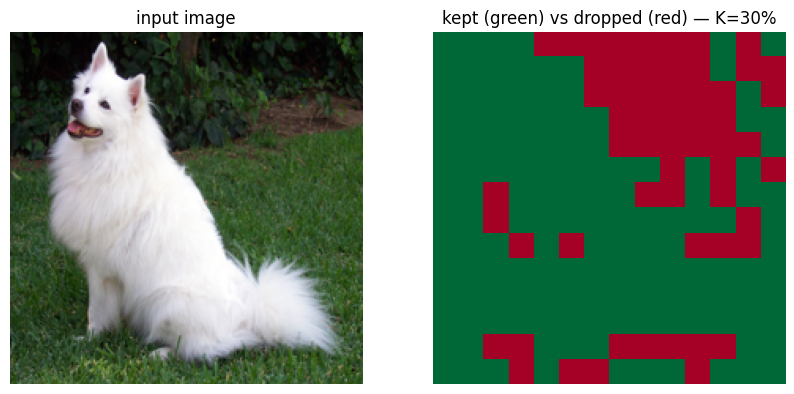

In [7]:
# Visualize which patches got dropped vs kept, on the 14x14 grid
mask_grid = np.ones(196)
mask_grid[drop_idx.cpu().numpy()] = 0
mask_grid = mask_grid.reshape(grid_h, grid_w)

fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(display_img)
axes[0].set_title("input image")
axes[1].imshow(mask_grid, cmap="RdYlGn", vmin=0, vmax=1)
axes[1].set_title(f"kept (green) vs dropped (red) — K={K_PERCENT}%")
for ax in axes:
    ax.axis("off")
plt.show()

## 2. The pruning wrapper
Kept indices are re-sorted into their original order; the keep count is fixed per batch so the tensor stays rectangular.

In [ ]:
import torch
from torch import nn

class PrunedViT(nn.Module):
    """Runs blocks 0..prune_layer (inclusive), scores patches by CLS->patch attention
    captured inside block `prune_layer`, drops the lowest-scoring `drop_frac` of patches,
    then runs the remaining blocks on the shorter sequence."""
    def __init__(self, model, prune_layer=6, drop_frac=0.3):
        super().__init__()
        self.model, self.prune_layer, self.drop_frac = model, prune_layer, drop_frac
        attn = model.blocks[prune_layer].attn
        attn.fused_attn = False              # force eager path so the attention matrix exists
        self._attn = None
        attn.attn_drop.register_forward_hook(self._grab)
    def _grab(self, mod, inp, out):
        self._attn = inp[0]                  # (B, heads, N, N), post-softmax (dropout is a no-op in eval)
    def forward(self, x):
        m = self.model
        x = m.patch_embed(x); x = m._pos_embed(x); x = m.patch_drop(x); x = m.norm_pre(x)
        for blk in m.blocks[: self.prune_layer + 1]:
            x = blk(x)
        B, N, D = x.shape
        n_patches = N - 1
        n_drop = int(n_patches * self.drop_frac)
        if n_drop > 0:
            scores = self._attn.mean(dim=1)[:, 0, 1:]                           # (B, 196)
            kept = scores.topk(n_patches - n_drop, dim=1, largest=True).indices
            kept = kept.sort(dim=1).values                                      # keep original token order
            patches = x[:, 1:].gather(1, kept.unsqueeze(-1).expand(-1, -1, D))  # (B, n_keep, D)
            x = torch.cat([x[:, :1], patches], dim=1)                           # CLS + kept
        for blk in m.blocks[self.prune_layer + 1 :]:
            x = blk(x)
        x = m.norm(x)
        return m.forward_head(x)

pruner = PrunedViT(model, prune_layer=6, drop_frac=0.0)

## Check 1 — K=0% should reproduce the baseline (quick preview of Day 4)

In [8]:
# 1) true fused baseline
model.blocks[6].attn.fused_attn = True
with torch.no_grad():
    base = model(x)
model.blocks[6].attn.fused_attn = False   # wrapper needs the eager path

# 2) exercise the gather path with nothing dropped
pruner.drop_frac = 0.0
with torch.no_grad():
    pruner(x)                              # populates pruner._attn
    m = pruner.model
    h = m.norm_pre(m.patch_drop(m._pos_embed(m.patch_embed(x))))
    for blk in m.blocks[:7]:
        h = blk(h)
    scores = pruner._attn.mean(1)[:, 0, 1:]
    kept = scores.topk(196, dim=1).indices.sort(dim=1).values
    h2 = torch.cat([h[:, :1], h[:, 1:].gather(1, kept.unsqueeze(-1).expand(-1, -1, h.shape[-1]))], 1)
    #print("kept == arange:", torch.equal(kept[0], torch.arange(196)))
    print("kept == arange:", torch.equal(kept[0], torch.arange(196, device=kept.device)))
    print("gather is identity:", torch.equal(h, h2))
    print("fused vs wrapper max abs diff:", (base - pruner(x)).abs().max().item())

kept == arange: True
gather is identity: True
fused vs wrapper max abs diff: 1.430511474609375e-06


## Check 2 — sequence length really shrinks after block 6

In [9]:
seen = []
h = model.blocks[7].register_forward_hook(lambda m, i, o: seen.append(i[0].shape))
with torch.no_grad():
    for K in (0.0, 0.1, 0.3, 0.5):
        seen.clear(); pruner.drop_frac = K; pruner(x)
        print(f"K={K:.0%}: block 7 input shape {tuple(seen[0])}  (expected seq len {1 + 196 - int(196*K)})")
h.remove()

K=0%: block 7 input shape (1, 197, 768)  (expected seq len 197)
K=10%: block 7 input shape (1, 178, 768)  (expected seq len 178)
K=30%: block 7 input shape (1, 139, 768)  (expected seq len 139)
K=50%: block 7 input shape (1, 99, 768)  (expected seq len 99)


## Check 3 — do predictions survive pruning?

In [10]:
def top5(logits):
    p = logits.softmax(-1)[0]; v, i = p.topk(5); return [(int(a), round(float(b), 3)) for a, b in zip(i, v)]
with torch.no_grad():
    print("baseline:", top5(base))
    for K in (0.1, 0.3, 0.5, 0.7):
        pruner.drop_frac = K
        print(f"K={K:.0%}:    ", top5(pruner(x)))

baseline: [(258, 0.51), (259, 0.259), (261, 0.014), (154, 0.003), (257, 0.003)]
K=10%:     [(258, 0.516), (259, 0.255), (261, 0.014), (154, 0.003), (257, 0.003)]
K=30%:     [(258, 0.482), (259, 0.277), (261, 0.014), (154, 0.003), (257, 0.003)]
K=50%:     [(258, 0.497), (259, 0.252), (261, 0.014), (154, 0.003), (257, 0.003)]
K=70%:     [(258, 0.646), (259, 0.11), (261, 0.008), (248, 0.004), (257, 0.003)]


## Data: Imagenette val, 20 images per class (fixed seed)

In [ ]:
import os
import tarfile
from torchvision.datasets import ImageFolder
from torch.utils.data import DataLoader, Subset

if not os.path.exists("imagenette2-320"):
    urllib.request.urlretrieve("https://s3.amazonaws.com/fast-ai-imageclas/imagenette2-320.tgz", "imagenette.tgz")
    tarfile.open("imagenette.tgz").extractall(".")
ds = ImageFolder("imagenette2-320/val", transform=transform)

In [ ]:
import torch
IMAGENETTE_WNIDS = {  # wnid -> ImageNet-1k class index
 "n01440764":0,"n02102040":217,"n02979186":482,"n03000684":491,"n03028079":497,
 "n03394916":566,"n03417042":569,"n03425413":571,"n03445777":574,"n03888257":701}

@torch.no_grad()
def run_logits(fn, loader, device):
    outs = []
    for xb, _ in loader:
        outs.append(fn(xb.to(device)).cpu())
    return torch.cat(outs)

def metrics(logits, base_logits, y_in1k):
    pred, bpred = logits.argmax(1), base_logits.argmax(1)
    p = logits.softmax(-1); bp = base_logits.softmax(-1)
    idx = torch.arange(len(y_in1k))
    return dict(
        agree_top1 = (pred == bpred).float().mean().item(),
        acc        = (pred == y_in1k).float().mean().item(),
        ptrue      = p[idx, y_in1k].mean().item(),
        ptrue_drop = (bp[idx, y_in1k] - p[idx, y_in1k]).mean().item(),
        max_abs_diff_vs_base = (logits - base_logits).abs().max().item(),
    )

In [11]:
import random

wnids = ds.classes                                   # sorted wnid folder names
to_in1k = torch.tensor([IMAGENETTE_WNIDS[w] for w in wnids])
random.seed(0)
per_class = {c: [] for c in range(len(wnids))}
for i, (_, c) in enumerate(ds.samples): per_class[c].append(i)
idxs = [i for c in per_class for i in random.sample(per_class[c], 20)]
loader = DataLoader(Subset(ds, idxs), batch_size=16, shuffle=False)
y_in1k = to_in1k[torch.tensor([ds.samples[i][1] for i in idxs])]
print(len(idxs), "images")

200 images


## Baseline first (fused attention), THEN build the wrapper (it switches block 6 to the eager path)

In [12]:
base_logits = run_logits(model, loader, device)
print('baseline 1000-way top-1 on these images:', (base_logits.argmax(1) == y_in1k).float().mean().item())

baseline 1000-way top-1 on these images: 0.8999999761581421


In [ ]:
pruner = PrunedViT(model, prune_layer=6, drop_frac=0.0)

## 3. Accuracy and agreement vs drop fraction (200 images, block 6)
One image is 0.5 points at this sample size: this is a smoke test. The full-validation sweep is in part 2.

In [13]:
import pandas as pd
rows = []
for K in (0.0, 0.1, 0.3, 0.5, 0.7):
    pruner.drop_frac = K
    r = metrics(run_logits(pruner, loader, device), base_logits, y_in1k); r["K"] = K; rows.append(r)
df = pd.DataFrame(rows).set_index("K"); df

,agree_top1,acc,ptrue,ptrue_drop,max_abs_diff_vs_base
K,,,,,
0.0,1.00,0.900,0.741127,0.000000,0.000000
0.1,1.00,0.900,0.742379,-0.001252,0.882440
0.3,1.00,0.900,0.738340,0.002787,2.401383
0.5,0.96,0.890,0.717821,0.023306,4.967084
0.7,0.93,0.875,0.657454,0.083673,5.953107
